In [36]:
import torch
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import time
import numpy as np
import torch.nn as nn

In [ ]:
def visualize_pointcloud_sequence(pointcloud_tensor, pre_pointcloud_tensor, 
                                   start_t=0,
                                   depa=None, depb=None, interval=0.1):
    """
    visulize the nodes 

    :param pointcloud_tensor: [B, n, 3] tensor or numpy array, ground truth node displacements during indentation
    :param pre_pointcloud_tensor: [B, n, 3] tensor or numpy array, predicted node displacements during indentation
    :param depa: [B, n], indentation depth of pointcloud_tensor, for better visualization
    :param depb: [B, n], indentation depth of pre_pointcloud_tensor, for better visualization
    :param interval: time interval between frames (seconds)
    """
    to_numpy = lambda x: x.numpy() if hasattr(x, 'numpy') else x
    pointcloud_tensor = to_numpy(pointcloud_tensor)
    pre_pointcloud_tensor = to_numpy(pre_pointcloud_tensor)
    depa = to_numpy(depa) if depa is not None else None
    depb = to_numpy(depb) if depb is not None else None

    len_t, n, _ = pointcloud_tensor.shape
    fig = plt.figure(figsize=(12, 6))
    ax = fig.add_subplot(121, projection='3d')
    ax1 = fig.add_subplot(122, projection='3d')

    for t in range(start_t, len_t):
        clear_output(wait=True)
        ax.clear()
        ax1.clear()

        # modify the range of axes for better visualization, adjust it according to ur data
        for _ax in [ax, ax1]:
            if _ax is not None:
                _ax.set_xlim([0, 0.02])
                _ax.set_ylim([0, 0.02])
                _ax.set_zlim([-0.002, 0.01])
                _ax.grid(True)
                _ax.axis('off')

        ax.set_title(f'Time Step {t + 1}/{len_t}, z_deformation {np.sum((pointcloud_tensor[t, :, 2] - pointcloud_tensor[0, :, 2]) <= -0.001)}')
        ax1.set_title(f'Time Step {t + 1}/{len_t}, z_deformation {np.sum((pre_pointcloud_tensor[t, :, 2] - pointcloud_tensor[0, :, 2]) <= -0.001)}')

        pc = pointcloud_tensor[t]
        color_a = depa[t] if depa is not None else 'b'
        ax.scatter(pc[:, 0], pc[:, 1], pc[:, 2], c=color_a, cmap='plasma', vmin=0, vmax=np.max(depa) if depa is not None else None)

        pc1 = pre_pointcloud_tensor[t]
        color_b = depb[t] if depb is not None else 'r'
        ax1.scatter(pc1[:, 0], pc1[:, 1], pc1[:, 2], c=color_b, cmap='plasma', vmin=0, vmax=np.max(depb) if depb is not None else None)


        display(fig)
        time.sleep(interval)

    plt.close(fig)

In [3]:
def plot_deformation_field_move(points_3d, displacements, time_step=0, scale=150.0, interval=0.1):
    """
    draw the displacement field of the surface nodes in 2D plane.
    
    Parameters:
    - points_3d: numpy array, shape [n, 3], representing the initial 3D coordinates of the points.
    - displacements: numpy array, shape [B, n, 3], representing the displacements at B time steps.
    - time_step: the time step index to visualize.
    - scale: the scaling factor for the displacement arrows.
    """
    # time_step: start point

    #fig = plt.figure(figsize=(8, 8))

    xy_pos = points_3d[:, :2]
    min_xy = xy_pos.min(axis=0)
    max_xy = xy_pos.max(axis=0)
    range_xy = max_xy - min_xy
    #scale_xy = 1.0 / (range_xy.max() + 1e-8)
    xy_pos_scaled = (xy_pos) * 100  # scale up about 100 times for better visualization

    fig, ax = plt.subplots(figsize=(8, 8))
    num_time_steps = displacements.shape[0]

    for t in range(time_step, num_time_steps):
        clear_output(wait=True)
        ax.clear()

        disp = displacements[t]  # [n, 3]

        
        dx_dy = disp[:, :2]  # [n, 2]
        dz = disp[:, 2]
        dz_abs = np.abs(dz)
        dz_norm = dz_abs / (dz_abs.max() + 1e-8)  # normalize to [0, 1]

        # Green = (0,1,0), Red = (1,0,0)
        colors = np.stack([dz_norm, 1 - dz_norm, np.zeros_like(dz_norm)], axis=1)
        

        ax.quiver(
            xy_pos_scaled[:, 0], xy_pos_scaled[:, 1],      # starting points of arrows
            dx_dy[:, 0] * scale, dx_dy[:, 1] * scale,      # arrows directions
            color=colors, angles='xy', scale_units='xy', scale=0.5, width=0.005
        )
        
        ax.scatter(xy_pos_scaled[:, 0], xy_pos_scaled[:, 1], c='green', s=10, alpha=0.3, label='Original Points')
        ax.grid(False)
        ax.axis('equal')
        ax.set_title(f'Deformation Field at Time Step {t}')

        display(fig)

        time.sleep(interval)

    plt.close(fig)


In [ ]:
vis_data = torch.load('data/vis_data/example/test_results.pth')

In [38]:
pred, truth, ori_pts, active_masks = vis_data['res'], vis_data['truth'], vis_data['ori'], vis_data['active_masks']

In [39]:
# since we only predicted the displacements of passive nodes, we need to assign the displacements of active nodes for the predicted results
active_masks_ = active_masks.unsqueeze(-1).expand_as(pred)
pred_full = truth.clone()
pred_full = torch.where(active_masks_, pred_full, pred)

## 1. visualize the point cloud sequence

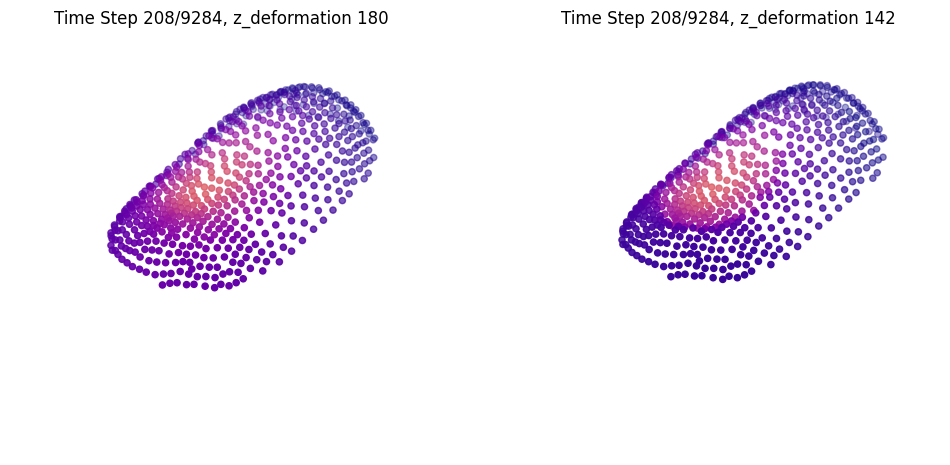

KeyboardInterrupt: 

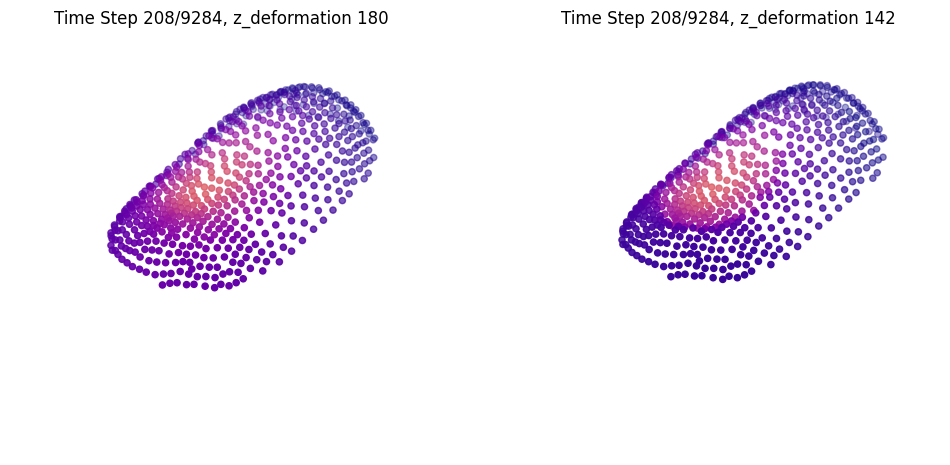

In [ ]:
# left: ground truth output by FEM, right: predicted by ETac

pred_dep = torch.abs(pred_full[:, :, 2])
truth_dep = torch.abs(truth[:, :, 2])

pred_pts = ori_pts + pred_full
truth_pts = ori_pts + truth

visualize_pointcloud_sequence(truth_pts, pred_pts, depa=truth_dep, depb=pred_dep, interval=0.1)

## 2. visualize the displacement field in 2D plane

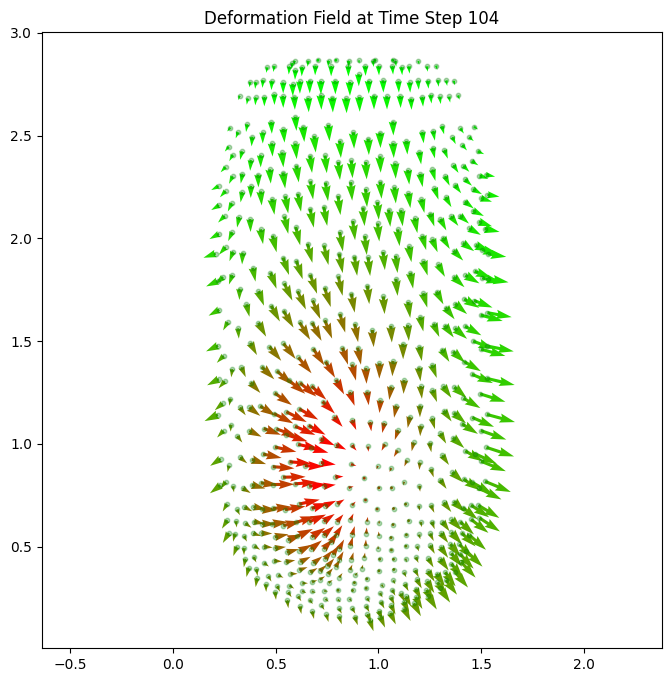

KeyboardInterrupt: 

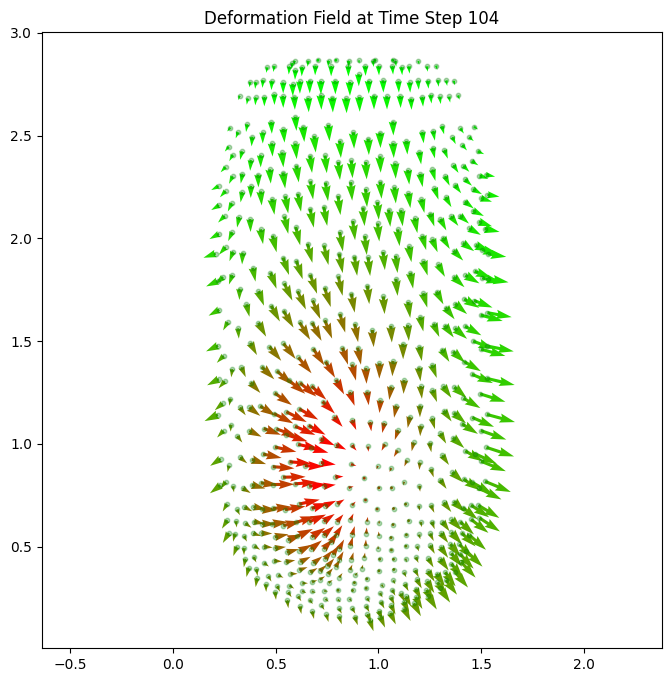

In [43]:
## ground truth
original = ori_pts[0].clone().detach()
truth_displacements = truth.clone().detach()
plot_deformation_field_move(original.numpy(), truth_displacements.numpy(), scale=100.0, interval=0.1)

KeyboardInterrupt: 

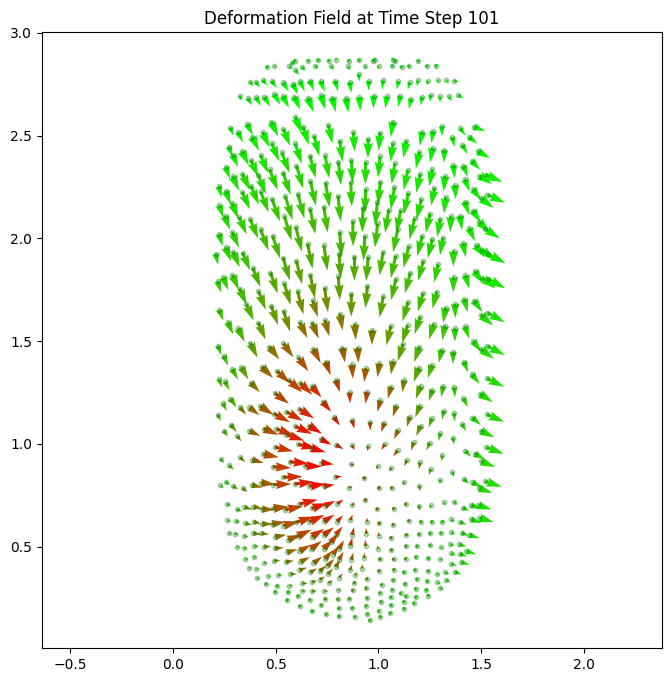

In [ ]:
## predicted by ETac

pred_displacements = pred_full.clone().detach()
plot_deformation_field_move(original.numpy(), pred_displacements.numpy(), scale=100.0, interval=0.1)

In [46]:
loss_fn = nn.MSELoss()
loss = loss_fn(pred_full, truth)
rmse = torch.sqrt(loss)
print(f'RMSE of predicted displacements: {rmse.item()*1e3} mm')

RMSE of predicted displacements: 0.14982557331677526 mm
